# 01 — Optimizers From Scratch: SGD, Momentum, AdaGrad, RMSProp, Adam, Schedules

**Overview:** implement every major gradient descent variant from scratch on the same loss
surface, compare convergence, then implement a learning-rate warmup + decay schedule.

**Required libraries:** `numpy`, `matplotlib`.

Connects to: `07_regression` (gradient descent from scratch) and Day 1's `05_ml_mathematics`
(the gradient). Leads to: `11_generalization` and, eventually, Day 3's PyTorch `torch.optim`,
which implements exactly these update rules.

## 0. Environment & a shared, slightly tricky loss surface

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# An elongated quadratic bowl: much steeper in one direction than the other.
# This is specifically chosen because plain gradient descent struggles with it (it oscillates
# across the steep direction while crawling along the shallow one) -- exactly the situation
# momentum and adaptive methods are designed to help with.
A = np.array([50.0, 1.0])   # curvature per dimension

def loss_fn(theta):
    return 0.5 * np.sum(A * theta**2)

def grad_fn(theta):
    return A * theta

start_point = np.array([1.0, 1.0])
n_steps = 100
print("start point:", start_point, "start loss:", loss_fn(start_point))


start point: [1. 1.] start loss: 25.5


## 1. Plain (batch) gradient descent

**Equation:** `θ ← θ - η∇L(θ)`

In [2]:
def run_gd(lr, n_steps=n_steps):
    theta = start_point.copy()
    history = [theta.copy()]
    for _ in range(n_steps):
        theta = theta - lr * grad_fn(theta)
        history.append(theta.copy())
    return np.array(history)

history_gd = run_gd(lr=0.015)
print("final theta (plain GD):", history_gd[-1], "final loss:", loss_fn(history_gd[-1]))


final theta (plain GD): [6.22301528e-61 2.20608910e-01] final loss: 0.024334145689245138


## 2. SGD vs mini-batch SGD (concept, simulated noise)

💡 **Intuition:** since there's no dataset here, we simulate SGD's noise by adding random
perturbation to the true gradient, scaled down for mini-batches (larger batch = less noise,
connecting to Day 1's sampling/standard-error ideas).

In [3]:
def run_noisy_gd(lr, noise_scale, n_steps=n_steps, seed=0):
    local_rng = np.random.default_rng(seed)
    theta = start_point.copy()
    history = [theta.copy()]
    for _ in range(n_steps):
        noisy_grad = grad_fn(theta) + local_rng.normal(scale=noise_scale, size=2)
        theta = theta - lr * noisy_grad
        history.append(theta.copy())
    return np.array(history)

history_sgd = run_noisy_gd(lr=0.015, noise_scale=3.0)       # high noise: single-example SGD
history_minibatch = run_noisy_gd(lr=0.015, noise_scale=0.5)  # lower noise: mini-batch SGD

print("final loss, pure SGD (high noise):      ", loss_fn(history_sgd[-1]))
print("final loss, mini-batch SGD (less noise):", loss_fn(history_minibatch[-1]))
print("Larger batches reduce gradient noise -- the same bias/variance idea from Day 1's sampling topic.")


final loss, pure SGD (high noise):       0.03413758211595717
final loss, mini-batch SGD (less noise): 0.019595346099199662
Larger batches reduce gradient noise -- the same bias/variance idea from Day 1's sampling topic.


## 3. Momentum

**Equations:** `v ← βv + ∇L(θ)`, `θ ← θ - ηv`

💡 **Intuition:** accumulating a moving average of gradients smooths out oscillation across the
steep dimension while building speed along the shallow one.

In [4]:
def run_momentum(lr, beta=0.9, n_steps=n_steps):
    theta = start_point.copy()
    v = np.zeros_like(theta)
    history = [theta.copy()]
    for _ in range(n_steps):
        v = beta * v + grad_fn(theta)
        theta = theta - lr * v
        history.append(theta.copy())
    return np.array(history)

history_momentum = run_momentum(lr=0.015)
print("final theta (momentum):", history_momentum[-1], "final loss:", loss_fn(history_momentum[-1]))


final theta (momentum): [-0.00168975  0.00029607] final loss: 7.142502113085133e-05


## 4. AdaGrad, RMSProp, Adam

**AdaGrad:** `G ← G + ∇L²`, `θ ← θ - η∇L/√(G+ε)` — learning rate per-parameter shrinks forever.

**RMSProp:** `G ← γG + (1-γ)∇L²` — exponential moving average instead of a running sum, so the
effective learning rate doesn't vanish.

**Adam:** combines a momentum-style first moment `m` with an RMSProp-style second moment `v`,
plus bias correction for early steps.

In [5]:
def run_adagrad(lr, n_steps=n_steps, eps=1e-8):
    theta = start_point.copy()
    G = np.zeros_like(theta)
    history = [theta.copy()]
    for _ in range(n_steps):
        g = grad_fn(theta)
        G += g**2
        theta = theta - lr * g / (np.sqrt(G) + eps)
        history.append(theta.copy())
    return np.array(history)

def run_rmsprop(lr, gamma=0.9, n_steps=n_steps, eps=1e-8):
    theta = start_point.copy()
    G = np.zeros_like(theta)
    history = [theta.copy()]
    for _ in range(n_steps):
        g = grad_fn(theta)
        G = gamma * G + (1 - gamma) * g**2
        theta = theta - lr * g / (np.sqrt(G) + eps)
        history.append(theta.copy())
    return np.array(history)

def run_adam(lr, beta1=0.9, beta2=0.999, n_steps=n_steps, eps=1e-8):
    theta = start_point.copy()
    m, v = np.zeros_like(theta), np.zeros_like(theta)
    history = [theta.copy()]
    for t in range(1, n_steps + 1):
        g = grad_fn(theta)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g**2
        m_hat = m / (1 - beta1**t)      # bias correction
        v_hat = v / (1 - beta2**t)
        theta = theta - lr * m_hat / (np.sqrt(v_hat) + eps)
        history.append(theta.copy())
    return np.array(history)

history_adagrad = run_adagrad(lr=0.5)
history_rmsprop = run_rmsprop(lr=0.05)
history_adam = run_adam(lr=0.1)

for name, h in [("AdaGrad", history_adagrad), ("RMSProp", history_rmsprop), ("Adam", history_adam)]:
    print(f"{name:10s} final theta={h[-1].round(4)}  final loss={loss_fn(h[-1]):.6f}")


AdaGrad    final theta=[0. 0.]  final loss=0.000000
RMSProp    final theta=[0.0245 0.0245]  final loss=0.015367
Adam       final theta=[0.0029 0.0029]  final loss=0.000220


## 5. Compare all optimizers' convergence on the same loss surface

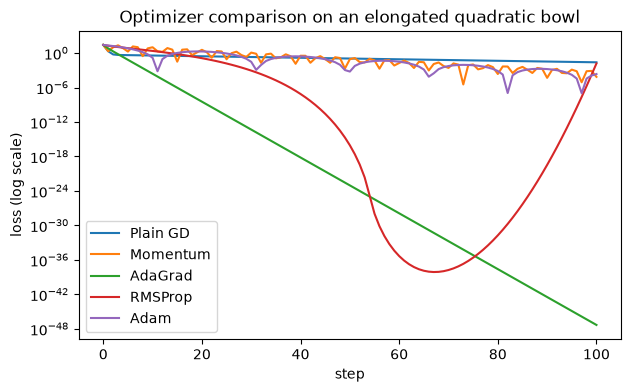


All optimizers reduce loss from the starting point; they differ in path and speed, not in whether they eventually get there on this convex problem.


In [6]:
all_runs = {
    "Plain GD": history_gd,
    "Momentum": history_momentum,
    "AdaGrad": history_adagrad,
    "RMSProp": history_rmsprop,
    "Adam": history_adam,
}

fig, ax = plt.subplots(figsize=(7, 4))
for name, h in all_runs.items():
    losses = [loss_fn(theta) for theta in h]
    ax.plot(losses, label=name)
ax.set_yscale("log")
ax.set_xlabel("step"); ax.set_ylabel("loss (log scale)")
ax.set_title("Optimizer comparison on an elongated quadratic bowl")
ax.legend()
plt.show()

# All should eventually converge to (very close to) 0 loss at the origin.
for name, h in all_runs.items():
    assert loss_fn(h[-1]) < loss_fn(h[0])
print("\nAll optimizers reduce loss from the starting point; they differ in path and speed, "
      "not in whether they eventually get there on this convex problem.")


## 6. Learning-rate schedule: linear warmup + cosine decay

💡 **Intuition:** warmup avoids a large, potentially destabilizing update right at
initialization (when gradients can be poorly scaled); decay lets the optimizer settle into a
sharper minimum later in training.

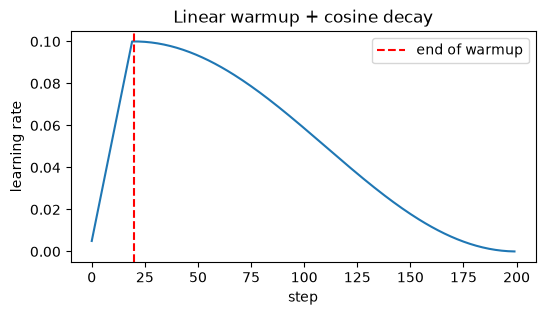

In [7]:
def warmup_cosine_schedule(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps:
        return base_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return base_lr * 0.5 * (1 + np.cos(np.pi * progress))

total_steps = 200
warmup_steps = 20
base_lr = 0.1
schedule = [warmup_cosine_schedule(s, total_steps, warmup_steps, base_lr) for s in range(total_steps)]

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(schedule)
ax.axvline(warmup_steps, color="red", linestyle="--", label="end of warmup")
ax.set_xlabel("step"); ax.set_ylabel("learning rate"); ax.set_title("Linear warmup + cosine decay")
ax.legend()
plt.show()

assert schedule[0] < schedule[warmup_steps - 1]          # increasing during warmup
assert schedule[warmup_steps] > schedule[-1]              # decreasing during decay
assert schedule[-1] < 1e-3                                 # decays close to 0 by the end


## 7. Connection to what's next

Every update rule implemented here (`SGD`, `Adam`, `AdamW`) exists as a one-line
`torch.optim.X(model.parameters(), lr=...)` call in Day 3 — understanding the internals here
means Day 3's `torch.optim` and `torch.optim.lr_scheduler` will never feel like black boxes.

## 8. Interview questions
1. Why does plain gradient descent oscillate on an elongated loss surface, and how does momentum fix it?
2. Why does AdaGrad's learning rate shrink to (effectively) zero over a long training run?
3. What two things does Adam combine, and why does it need bias correction early in training?
4. Why would you use a warmup period instead of just starting at your target learning rate?
5. What's the practical difference between AdamW and Adam + L2 regularization?

## 9. Exercises
1. Make the loss surface even more elongated (`A = [200, 1]`) and compare plain GD vs momentum vs Adam's convergence speed.
2. Implement AdamW (decoupled weight decay) and compare its trajectory to Adam when a weight-decay term is added.
3. Replace the cosine decay schedule with a step-decay schedule (halve LR every 50 steps) and compare the resulting loss curves.

## 10. Summary

✅ Mini-batch SGD is the practical default; momentum smooths noisy/oscillating updates; AdaGrad/
RMSProp/Adam adapt the learning rate per parameter; learning-rate schedules (warmup + decay)
stabilize early training and sharpen convergence late. Next: `11_generalization`.